# 직접 해보기: Elliptic Envelope (원본 데이터부터)

이전 노트북의 피처·함수는 쓰지 않고, 원본 CSV만으로 처음부터 진행합니다.

- `data/train.csv`: ID, V1~V30 (정답 없음)
- `data/val.csv`: ID, V1~V30, Class (사기=1)
- `data/test.csv`: ID, V1~V30
- `data/sample_submission.csv`: 제출 형식 (ID, Class)

In [1]:
%pip install tqdm
%pip install torch


Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import random
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from sklearn.ensemble import IsolationForest
from sklearn.covariance import EllipticEnvelope
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from sklearn.decomposition import PCA

import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings(action='ignore')

train = pd.read_csv('../data/train.csv')
val = pd.read_csv('../data/val.csv')
test = pd.read_csv('../data/test.csv')

print('train:', train.shape, '/ val:', val.shape, '/ test:', test.shape)

train: (113842, 31) / val: (28462, 32) / test: (142503, 31)


In [3]:
train.head()

,ID,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,V29,V30
0,3,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,4.983721,-0.994972
1,4,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,1.418291,-0.994972
2,6,-0.425966,0.960523,1.141109,-0.168252,0.420987,-0.029728,0.476201,0.260314,-0.568671,...,-0.208254,-0.559825,-0.026398,-0.371427,-0.232794,0.105915,0.253844,0.081080,-0.256131,-0.994960
3,8,-0.644269,1.417964,1.074380,-0.492199,0.948934,0.428118,1.120631,-3.807864,0.615375,...,1.943465,-1.015455,0.057504,-0.649709,-0.415267,-0.051634,-1.206921,-1.085339,0.262698,-0.994901
4,9,-0.894286,0.286157,-0.113192,-0.271526,2.669599,3.721818,0.370145,0.851084,-0.392048,...,-0.073425,-0.268092,-0.204233,1.011592,0.373205,-0.384157,0.011747,0.142404,0.994900,-0.994901


In [4]:
val.head()

,ID,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,V29,V30,Class
0,10,-0.338262,1.119593,1.044367,-0.222187,0.499361,-0.246761,0.651583,0.069539,-0.736727,...,-0.633753,-0.120794,-0.385050,-0.069733,0.094199,0.246219,0.083076,-0.255991,-0.994878,0
1,22,0.962496,0.328461,-0.171479,2.109204,1.129566,1.696038,0.107712,0.521502,-1.191311,...,0.402492,-0.048508,-1.371866,0.390814,0.199964,0.016371,-0.014605,0.168937,-0.994784,0
2,63,1.145524,0.575068,0.194008,2.598192,-0.092210,-1.044430,0.531588,-0.241888,-0.896287,...,-0.119703,-0.076510,0.691320,0.633984,0.048741,-0.053192,0.016251,0.169496,-0.994502,0
3,69,0.927060,-0.323684,0.387585,0.544474,0.246787,1.650358,-0.427576,0.615371,0.226278,...,0.079359,0.096632,-0.992569,0.085096,0.377447,0.036096,-0.005960,0.331307,-0.994467,0
4,83,-3.005237,2.600138,1.483691,-2.418473,0.306326,-0.824575,2.065426,-1.829347,4.009259,...,-0.181268,-0.163747,0.515821,0.136318,0.460054,-0.251259,-1.105751,-0.287012,-0.994373,0


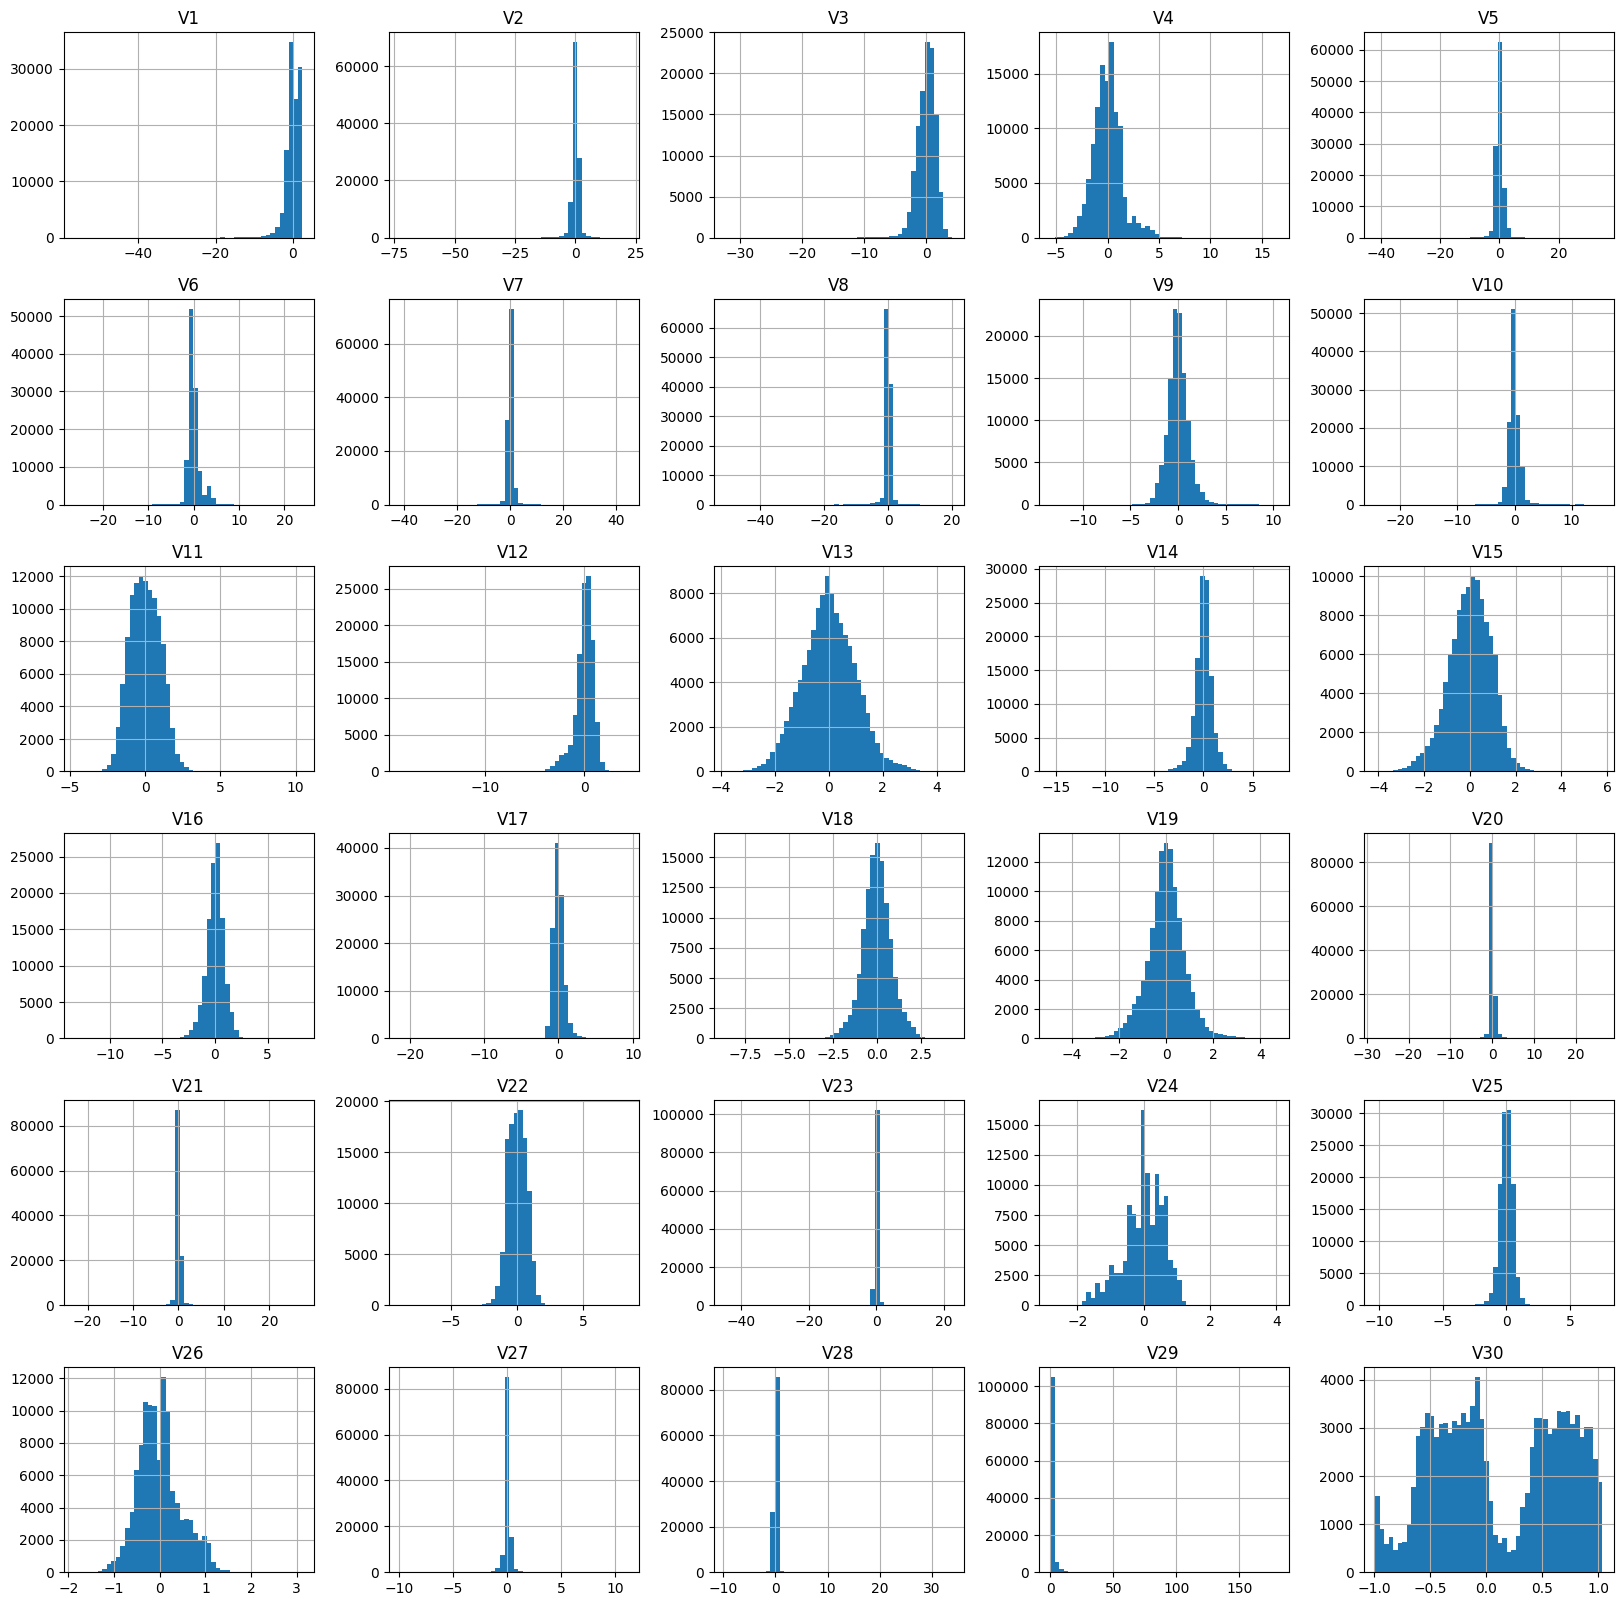

In [5]:
train.drop(columns=['ID']).hist(bins=50, figsize=(20,20))
plt.show()

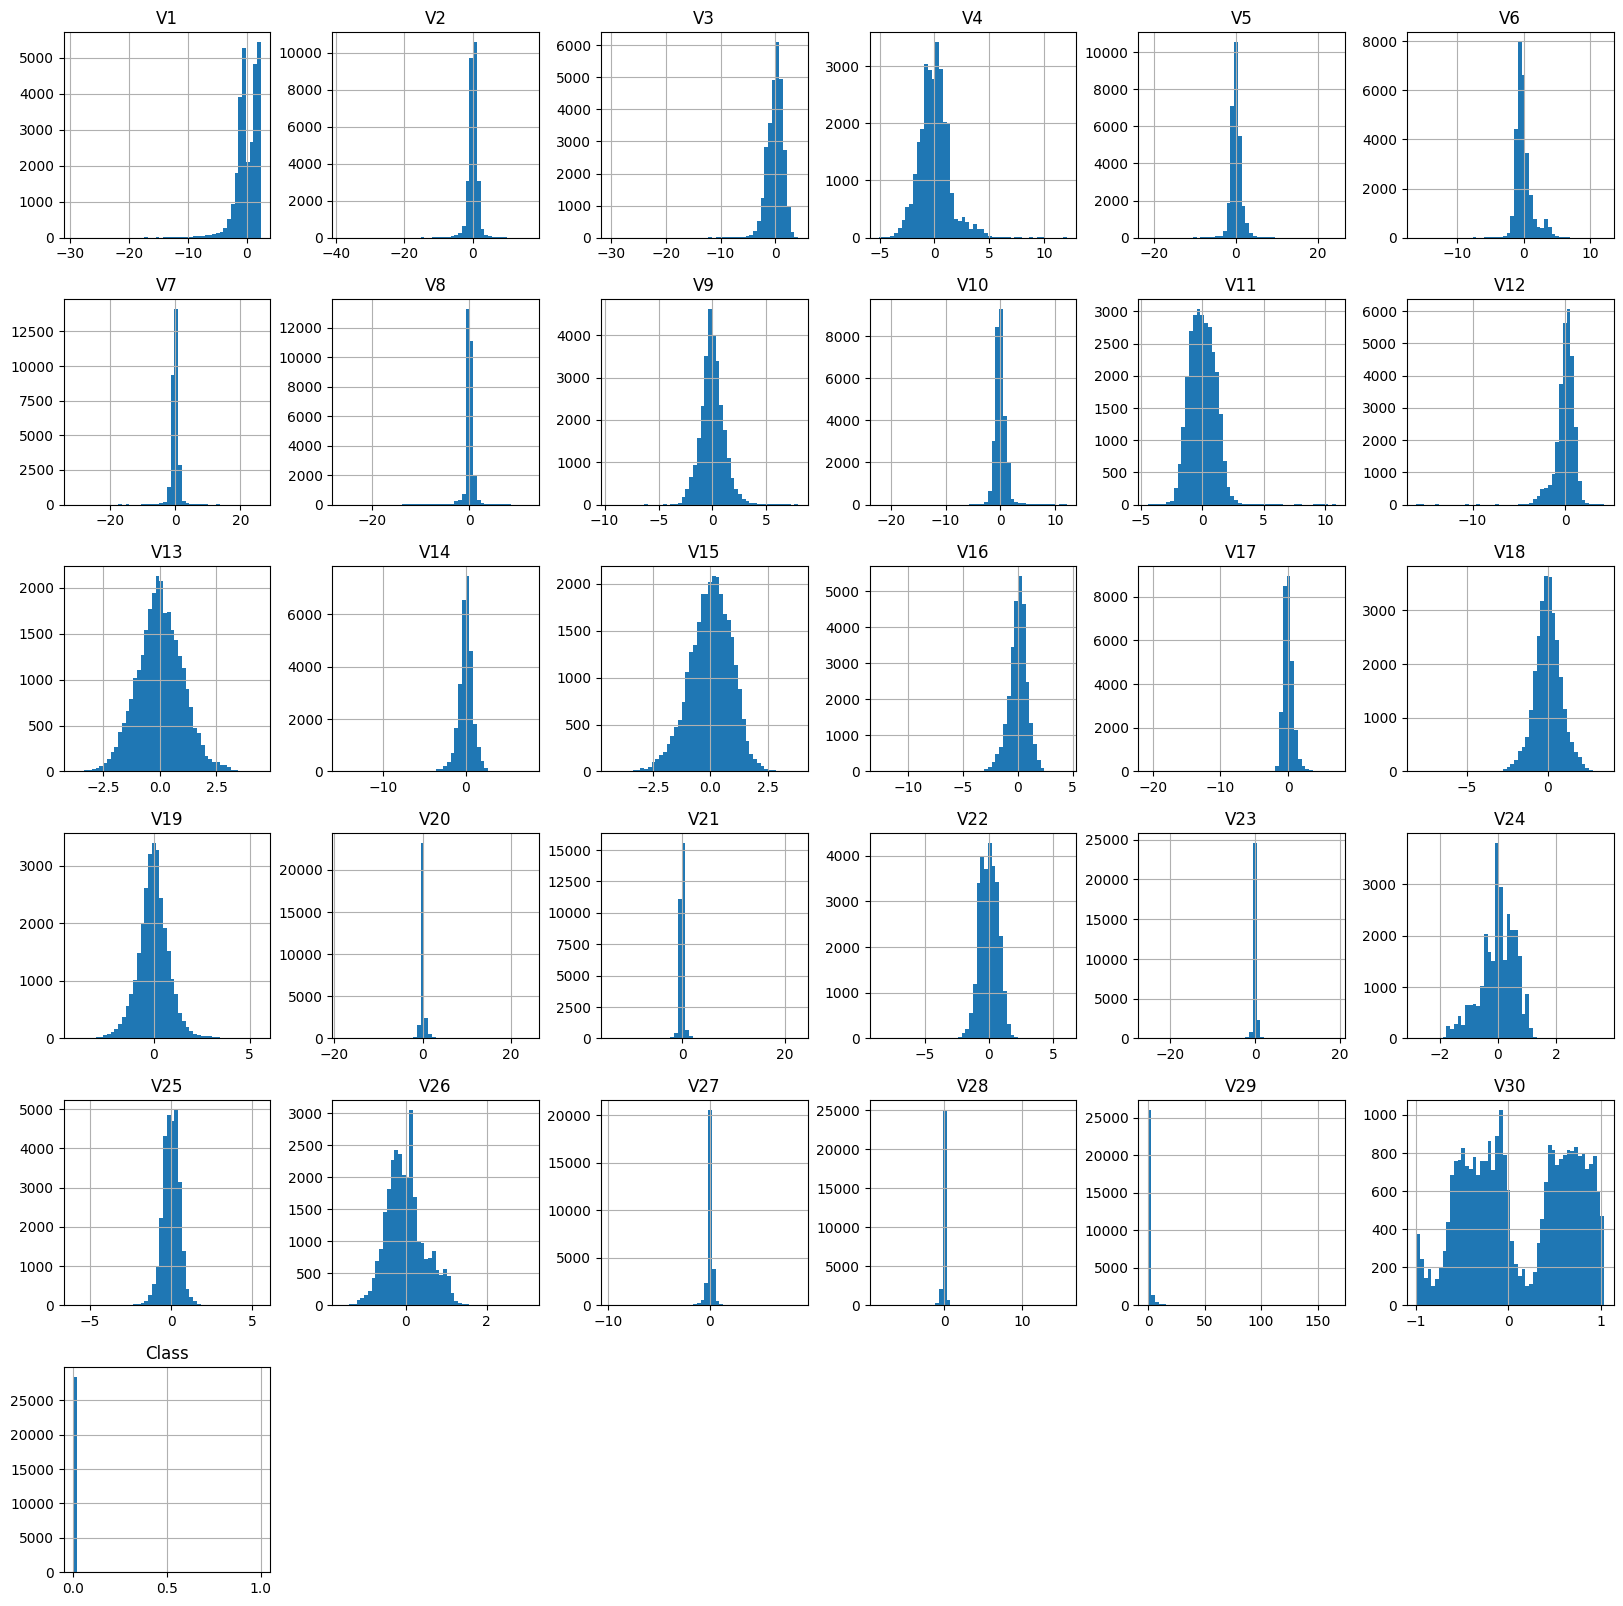

In [6]:
val.drop(columns=['ID']).hist(bins=50, figsize=(20,20))
plt.show()

In [7]:
val_normal, val_fraud=val['Class'].value_counts()
val_contamination = val_fraud / val_normal
print(f'val_contamination: {val_contamination}')

val_contamination: 0.0010551491277433877


In [8]:
train_x = train.drop(columns=["ID"])

In [9]:
pca_model=PCA(n_components=2)
pca_model.fit(train_x)
pca_x=pca_model.transform(train_x)

In [10]:
pca_x.shape

(113842, 2)

In [11]:
re_pca_x = pca_x.reshape(2,-1)
re_pca_x

array([[  4.50543791,  -0.82527886,   0.59692952, ...,  -0.93574395,
         -1.28726651,   1.26292192],
       [ -1.35067473,   1.08277948,  -1.27829526, ...,  -0.1197507 ,
         -1.48161661, -12.53317251]])

In [12]:
train_x['PCA_1']=re_pca_x[0].reshape(-1,1)
train_x['PCA_2']=re_pca_x[1].reshape(-1,1)

In [13]:
train_x.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V23,V24,V25,V26,V27,V28,V29,V30,PCA_1,PCA_2
0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,4.983721,-0.994972,4.505438,-1.350675
1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,1.418291,-0.994972,-0.825279,1.082779
2,-0.425966,0.960523,1.141109,-0.168252,0.420987,-0.029728,0.476201,0.260314,-0.568671,-0.371407,...,-0.026398,-0.371427,-0.232794,0.105915,0.253844,0.081080,-0.256131,-0.994960,0.596930,-1.278295
3,-0.644269,1.417964,1.074380,-0.492199,0.948934,0.428118,1.120631,-3.807864,0.615375,1.249376,...,0.057504,-0.649709,-0.415267,-0.051634,-1.206921,-1.085339,0.262698,-0.994901,-1.028132,1.252004
4,-0.894286,0.286157,-0.113192,-0.271526,2.669599,3.721818,0.370145,0.851084,-0.392048,-0.410430,...,-0.204233,1.011592,0.373205,-0.384157,0.011747,0.142404,0.994900,-0.994901,-1.367485,-1.301515


In [ ]:
model = EllipticEnvelope(support_fraction=0.994, contamination=val_contamination, random_state=42)
model.fit(train_x)

EllipticEnvelope(contamination=0.0010551491277433877, random_state=42,
                 support_fraction=0.994)

In [15]:
def get_pred_label(model_pred):
    model_pred = np.where(model_pred == 1, 0, model_pred)
    model_pred = np.where(model_pred == -1, 1, model_pred)
    return model_pred

In [17]:
val_x = val.drop(columns=['ID','Class']) # Input Data
val_y = val["Class"] # Label

pca_val_x = pca_model.transform(val_x)
re_pca_val_x = pca_val_x.reshape(2,-1)

val_x["PCA_1"] = re_pca_val_x[0].reshape(-1,1)
val_x["PCA_2"] = re_pca_val_x[1].reshape(-1,1)

val_pred = model.predict(val_x)
val_pred = get_pred_label(val_pred)
val_score = f1_score(val_y, val_pred, average='macro')
print(f'Validation F1 Score: {val_score}')
print(classification_report(val_y,val_pred))

Validation F1 Score: 0.8927516353661109
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     28432
           1       0.85      0.73      0.79        30

    accuracy                           1.00     28462
   macro avg       0.92      0.87      0.89     28462
weighted avg       1.00      1.00      1.00     28462



In [18]:
test_x = test.drop(columns=['ID'])

pca_test_x = pca_model.transform(test_x)
re_pca_test_x = pca_test_x.reshape(2,-1)

test_x["PCA_1"] = re_pca_test_x[0].reshape(-1,1)
test_x["PCA_2"] = re_pca_test_x[1].reshape(-1,1)

In [19]:
test_pred = model.predict(test_x) # model prediciton
test_pred = get_pred_label(test_pred)

In [21]:
submit = pd.read_csv('../data/sample_submission.csv')

In [23]:
submit['Class']=test_pred
submit.to_csv('../submissions/submit.csv', index=False)

# 리더보드 점수
public: 0.9248241501

private: 0.9105133393

## 분석: 왜 support_fraction=0.994에서 통했나

**리더보드: Public 0.9248 / Private 0.9105 (현재 최고)**. 기본값으로 돌리면 val macro-F1 0.4995(무작위 수준)인데, 이 값 하나로 결과가 바뀌었습니다.

### support_fraction이 하는 일
Elliptic Envelope 안에서는 MCD(Minimum Covariance Determinant)가 "정상 기준"(평균·공분산)을 잡습니다. 두 단계로 진행돼요.
1. **1차(raw):** 전체 중 `support_fraction` 비율만큼의 부분집합 가운데, 공분산 행렬식(퍼진 부피)이 가장 작은 것을 찾습니다.
2. **재가중(reweighting):** 1차 기준으로 마할라노비스 거리를 재서 카이제곱 97.5% 분위수 안에 드는 점만 남기고 공분산을 다시 계산합니다.

기본값(None)은 약 50%만 씁니다. "데이터의 절반까지 이상치일 수 있다"는 가장 보수적인 가정이에요.
그런데 이 데이터는 사기가 0.1%뿐이고, 거래의 88%가 정확히 한 평면 위에 있습니다(03b 참고).
50%만 고르면 평면 위의 점만으로 부분집합을 채울 수 있어서, 평면에 수직인 방향의 두께가 0이 되고 공분산이 깨집니다(exact fit).

`support_fraction`을 0.994로 올리면 "가장 튀는 0.6%만 빼고 다 쓴다"는 뜻입니다. 평면 밖 정상 거래가 기준에 강제로 들어가서
평면 방향에도 작지만 0이 아닌 두께가 생기고, 평면 밖 사기는 그 얇은 두께에 비해 아주 멀리 있는 점으로 잡힙니다.

### 확인할 것
`support_fraction`을 바꿔가며 1차 공분산과 재가중 공분산으로 각각 채점하고, 공분산이 얼마나 건강한지(조건수, 최소 고유값)도 같이 봅니다.
- 조건수(cond) = 가장 큰 분산 ÷ 가장 작은 분산. 1e16 이상이면 사실상 역행렬을 구할 수 없는 상태입니다.
- 위 셀들의 PCA 열은 쓰지 않고 V1~V30만 씁니다 (PCA 열의 문제는 아래 정리에서 설명).

support_fraction 하나당 30초~3분, 전체 5~7분 걸립니다.

In [ ]:
import time
from scipy.linalg import pinvh
from sklearn.covariance import MinCovDet
from sklearn.metrics import average_precision_score

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# PCA 열 없이 원본 V1~V30만 사용
X_tr = train.drop(columns=['ID']).values
X_va = val.drop(columns=['ID', 'Class']).values
y_va = val['Class'].values

def maha_sq(loc, cov, X):
    # 마할라노비스 거리 제곱. EllipticEnvelope처럼 유사역행렬(pinvh)을 써서 결과를 맞춤
    d = X - loc
    return np.sum((d @ pinvh(cov)) * d, axis=1)

def score_row(sf, kind, loc, cov, n_subset):
    s_tr, s_va = maha_sq(loc, cov, X_tr), maha_sq(loc, cov, X_va)
    threshold = np.quantile(s_tr, 1 - val_contamination)   # train 점수 기준 (EllipticEnvelope.predict와 같은 방식)
    pred = (s_va >= threshold).astype(int)
    min_eig = max(np.linalg.eigvalsh(cov)[0], 0.0)   # 수치 오차로 생기는 아주 작은 음수(-1e-16 등)는 0으로
    return {'support_fraction': '기본값' if sf is None else sf, '공분산': kind,
            '사용한 점 수': int(n_subset),
            'val macro-F1': round(f1_score(y_va, pred, average='macro'), 4),
            '맞힌 사기(/30)': int((pred & y_va).sum()), '예측 건수': int(pred.sum()),
            'PR-AUC': round(average_precision_score(y_va, s_va), 4),
            '최소 고유값': min_eig, '조건수': np.linalg.cond(cov)}

sf_rows = []
for sf in [None, 0.9, 0.95, 0.99, 0.994, 0.999]:
    t0 = time.time()
    mcd = MinCovDet(support_fraction=sf, random_state=42).fit(X_tr)
    sf_rows.append(score_row(sf, '1차(raw)', mcd.raw_location_, mcd.raw_covariance_, mcd.raw_support_.sum()))
    sf_rows.append(score_row(sf, '재가중', mcd.location_, mcd.covariance_, mcd.support_.sum()))
    print(f'support_fraction={sf}: {time.time() - t0:.0f}초')

sf_table = pd.DataFrame(sf_rows)
display(sf_table.style.format({'최소 고유값': '{:.1e}', '조건수': '{:.1e}'}))

In [ ]:
labels = [str(v) for v in sf_table['support_fraction'].unique()]
x = np.arange(len(labels))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for kind, marker in [('1차(raw)', 'o'), ('재가중', 's')]:
    sub = sf_table[sf_table['공분산'] == kind]
    axes[0].plot(x, sub['val macro-F1'], marker=marker, label=kind)
    axes[1].plot(x, sub['조건수'], marker=marker, label=kind)

axes[0].set_title('support_fraction별 val macro-F1')
axes[0].axhline(0.5, color='gray', ls=':', label='무작위 수준')
axes[1].set_title('support_fraction별 공분산 조건수 (작을수록 건강)')
axes[1].set_yscale('log')
axes[1].axhline(1e16, color='red', ls=':', label='역행렬 불가 수준')
for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_xlabel('support_fraction')
    ax.legend()
plt.tight_layout()
plt.show()

### 정리

**1. 기본값이 실패한 이유는 "오염 비율 가정"이 틀려서다.**
기본값(약 50%)은 이상치가 절반까지 섞여 있어도 버티도록 만든 설정입니다. 이 데이터는 사기가 0.1%뿐인데 정상 거래 대부분이 한 평면에 몰려 있어서,
"절반만 골라라"는 규칙이 평면 위 점들만 고르는 함정이 됐습니다.
support_fraction을 실제 오염 비율에 맞게 1에 가깝게 잡는 것은 val을 보고 고른 값이 아니라, **데이터에 대한 가정을 맞춘 것**입니다.

**2. 0.99와 0.994 사이의 계단은 재가중 단계 때문이다.**
1차 공분산은 0.99부터 이미 0.8928을 냅니다. 그런데 재가중 단계는 카이제곱 97.5% 기준으로 점을 자르는데,
이 데이터는 꼬리가 두꺼워서 2.5%가 아니라 약 22%를 잘라냅니다. 그 과정에서 다시 평면 쪽으로 쏠려 공분산이 얇아지고 성능이 떨어집니다.
0.994는 재가중 후에도 두께가 남는 경계 근처 값입니다. 결과는 맞지만 **절벽 근처의 값**이라는 점은 기억해 둘 것.

**3. "강건한 기준"이라는 같은 교훈을 세 번째로 만났다.**
- Phase 2 마할라노비스: 극단값까지 다 넣어서 공분산을 계산 → 평면 방향 두께가 부풀려져 사기가 묻힘 (리더보드 0.66)
- 오토인코더: MSE 손실은 극단값까지 복원하려 함 → L1로 바꾸자 크게 개선 (리더보드 0.91)
- Elliptic Envelope: 가장 튀는 0.6%만 빼고 공분산 계산 → 최고 기록 (리더보드 0.92)

셋 다 "정상 기준을 잡을 때 극단값에 휘둘리지 않게 한다"는 같은 원리입니다.

**4. 위 셀들의 PCA 열은 실수였지만 결과에는 영향이 없었다.**
`pca_x.reshape(2, -1)`는 전치가 아니라서, PCA_1·PCA_2 열에 다른 거래들의 값이 섞여 들어갔습니다(올바른 PC1과의 상관 0.004).
의도대로라면 `pca_x[:, 0]`, `pca_x[:, 1]`이 맞습니다. 다만 올바르게 넣으면 오히려 val 0.8034로 떨어집니다.
PCA 성분은 V1~V30의 정확한 선형 조합이라 공분산이 다시 특이행렬(조건수 1e16)이 되기 때문입니다.
마할라노비스 계열 모델에는 **기존 변수의 선형 조합을 피처로 추가하면 안 된다**는 것도 교훈입니다.